# Mechanistic Pharmacokinetics and Pharmacodynamics Modelling, ODE Simulation \& Parameter Estimation

Mechanistic pharmacokinetic (PK) and pharmacodynamic (PD) models provide a quantitative framework for describing how drug exposure affects disease dynamics. By representing these processes through coupled ordinary differential equations (ODEs), such models can be used to reproduce observed trajectories and infer underlying biological parameters, useful for predicting how a biological system would respond to new treatment conditions.

A key challenge, however is that good predictive performance does not necessarily imply accurate recovery of the underlying population parameters. Nonlinear dynamics, noisy observations, parameter correlations, and the objective landscape can make parameter estimation sensitive to the choice of optimizer, parameterization and initialization.

This short study investigates these issues using a mechanistic PK/PD tumor-growth model and synthetic noisy data generated under multiple dosing scenarios. The analysis focuses on three related questions:

1. **How reliably can the model parameters be recovered from noisy observations?**
2. **How much does the optimization strategy and parameter scaling affect parameter estimation?**
3. **Does improved parameter recovery imply better out-of-sample predictive performance?**

To address these questions, weighted least-squares estimation is performed using different optimization strategies, including Powell and L-BFGS-B, with comparisons across parameter scalings and initial conditions. The resulting parameter estimates are evaluated against the known generating parameters and on held-out validation dataset, allowing parameter recovery and predictive generalization to be assessed separately.

### Key Findings


- The model exhibits **distinct response thresholds**: sufficiently slow absorption, high clearance, rapid tumor growth, weak inhibition, or large \(EC_{50}\) can prevent tumor shrinkage altogether, demonstrating strong nonlinear dependence of treatment response on PK/PD parameters.

- Under repeated dosing, the tumor can reach a **stable positive burden rather than being eradicated**, with treatment frequency and dose distribution strongly affecting the trajectory even when the total administered drug is comparable.

- Increasing dose accelerates tumor shrinkage but eventually encounters **pharmacodynamic saturation**, while sufficiently long gaps between doses allow tumor regrowth; importantly, the current model predicts **relapse after treatment cessation** rather than permanent eradication.

- Preliminary results indicate parameter non-identifiability, with **parameter recovery and predictive performance not aligned**: L-BFGS-B achieves lower parameter-recovery errors than Powell in the current experiments, while the Powell log-scaled configuration gives the lowest validation MSE ($=0.5978 ~\text{mm}^3$). The analysis is ongoing, with future experiments focusing on global-to-local optimization, multiple initializations, parameter identifiability, and systematic comparison of parameter recovery versus predictive generalization across treatment conditions.

### Import required libraries

In [860]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
import os
import time
import warnings

import math
import pandas as pd
import numpy as np   
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from scipy import stats
from scipy.optimize import minimize

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterGrid

## Pharmacokinetics and Pharmacodynamics for Tumor Drug

In this short project, we will study human body response to orally administered drug targetted at a tumor using a system of coupled ODEs.

Biological modelling conveniently captured by _compartments_ in the human body, where for the problem at hand we choose two distinct reservoirs necessary to model the drug concentration dynamics (the Pharmacokinetics) and the tumor dynamics (Pharmacodynamics).

Let us model the physiological process of a tumor responding to a drug as a two compartment process. The gastrointestinal compartment with an oral bioavailability of $1$, i.e. the entire amount of pill taken orally is available in the gut compartment, and the dynamics of the amount of drug evolves as,

\begin{align}
\dot{A}_g = -k_g A_g
\end{align}

where $A_g$ denotes the amount of drug in the gut compartment. From there, the drug is absorbed into the central compartment (consisting of blood, plasma, tissues) via first order dynamics, and leaves by clearance,

\begin{align}
\dot{A}_c = k_g A_g - \text{CL} \frac{A_c}{V} = k_g A_g - \text{CL} ~C(t)
\end{align}

where $A_c$ is the amount of drug in the central component, $C(t)$ is concentration of drug in the central compartment with apparent volume $V$. Finally, the tumor growth is inhibited according to the Emax model, given by,
\begin{align}
\dot{T} = r T \left(1-\frac{T}{K} \right) - \frac{E_{max} C}{\text{EC}_{50}+C} \,,
\end{align}
where the parameters are explained below. 

Intial conditions :
- $A_g$ $\text{mg}$ : Pill Dose
- $T_0$ $\text{mm}^3$ : Initial tumor size

Parameters : 
- $k_g$ : Fraction of gut drug absorbed into central compartment per unit time
- $CL$ : Clearance
- $V$ : apparent volume
- $K$ : carrying capacity
- $r$ : growth rate of tumor
- $E_{max}$ : maximum inhibition rate from drugs
- $\text{EC}_{50}$ : drug concentration $C(t)$ at which the inhibition rate achieved is half of $E_{max}$

In [ ]:
def pkpd_ode(t, y, theta):
    kg, CL, V, r, K, Emax, EC50 = theta
    Ag, Ac, T = y # values at time t
    C = Ac / V # Drug concentration
    drug_effect = Emax * C / (EC50 + C) # tumor inhibition as response to drug

    # PK PD ODE
    dAg_dt = -kg * Ag
    dAc_dt = kg * Ag - CL*C
    dT_dt = (r * T * (1 - T / K))- (drug_effect * T)

    return [dAg_dt, dAc_dt, dT_dt]

In [445]:
def pkpd_sol(pill_dose, T0, t_start, t_end, n_points, theta):
    Ag_0 = pill_dose
    Ac_0 = 0
    # initial conditions
    y0 = [Ag_0, Ac_0, T0]
    t_eval = np.linspace(t_start, t_end, n_points)
    
    sol = solve_ivp(pkpd_ode,(t_start, t_end), y0, t_eval=t_eval, args=(theta,))

    return sol

Let us explore the effect of varying parameter values and initial conditions, for a single drug dose and repeated dose regimen, on $A_g$, $A_c$ and $T$.

In [447]:
def single_dose_pkpd_plot(pill_dose, T0, t_start, t_end, n_points, theta, axes_Ag=None, axes_Ac=None, axes_T=None, label=None):
    # Solve coupled ODEs
    sol = pkpd_sol(pill_dose, T0, t_start, t_end, 100, theta)
    
    Ag = sol.y[0]
    Ac = sol.y[1]
    T = sol.y[2]
    
    C = Ac / V

    if axes_Ag is not None:
        axes_Ag.plot(sol.t, Ag, label=label)
    if axes_Ac is not None:
        axes_Ac.plot(sol.t, C, label=label)
    if axes_T is not None:
        axes_T.plot(sol.t, T, label=label)

### Visualizing effect of single dose

Let us explore the effect of varying $k_g$.

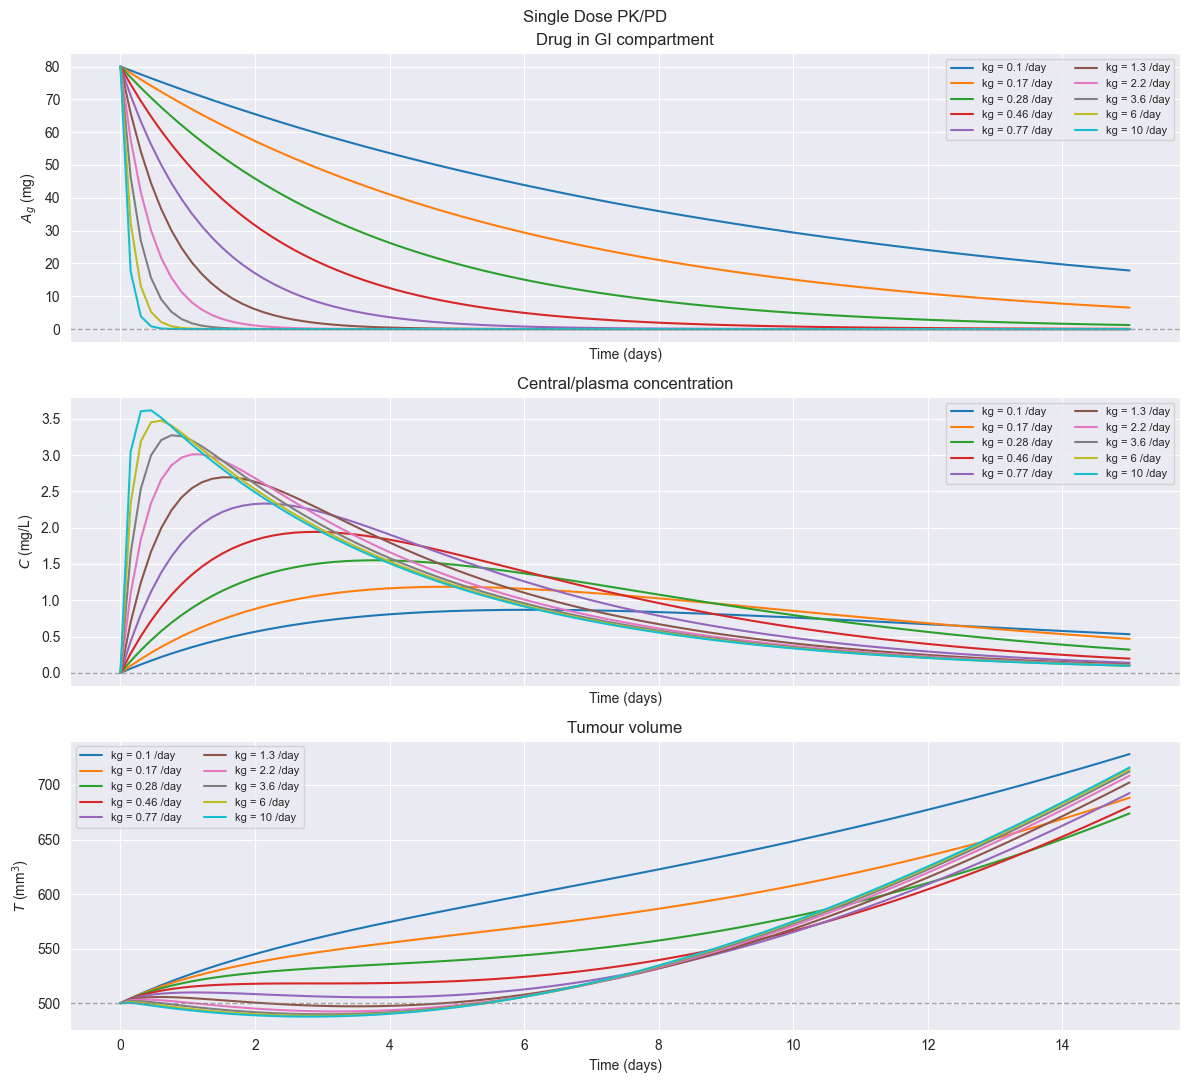

In [452]:
# Initial Condition
pill_dose = 80
T0 = 500

# Params    
CL = 5.0      
V = 20.0       
r = 0.08    
K = 2000.0       
Emax = 0.12     
EC50 = 2.0 

t_start=0
t_end=15
n_points=100

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

for kg in np.logspace(-1,1,10):
    theta = [kg, CL, V, r, K, Emax, EC50]

    single_dose_pkpd_plot(pill_dose, T0, t_start, t_end, n_points, theta, axes[0], axes[1], axes[2], f"kg = {kg:.2g} /day")


axes[0].axhline(y=0,ls='--',lw=1,color='gray',alpha=0.7)
axes[0].set_ylabel(r"$A_g$ (mg)")
axes[0].set_title("Drug in GI compartment")

axes[1].axhline(y=0,ls='--',lw=1,color='gray',alpha=0.7)
axes[1].set_ylabel(r"$C$ (mg/L)")
axes[1].set_title("Central/plasma concentration")

axes[2].axhline(y=T0,ls='--',lw=1,color='gray',alpha=0.7)
axes[2].set_ylabel(r"$T$ (mm$^3$)")
axes[2].set_title("Tumour volume")

for ax in axes:
    ax.set_xlabel("Time (days)")
    ax.tick_params('x')
    ax.legend(ncols=2, fontsize=8)

plt.suptitle('Single Dose PK/PD')
plt.tight_layout()
plt.show()

We find, keeping other parameters fixed,
- As the absorption rate into the central compartment increases, the drug amount in the gut $A_g$ falls to $0$ faster, naturally since it is absorbed faster into the central compartment.
- The peak central compartment concentration $C(t)_{max}$ is achieved later and at a smaller amount, and the drug lasts longer in the central compartment.
-  For smaller values of $k_g$, the tumor never shrinks (see curves for $k_g \leq 0.46 /\text{day}$), while it only temporarily shrinks below its original size for certain large values of $k_g$ (see curves for $k_g \geq 1.3 /\text{day}$).

We fix $k_g=2/\text{day}$, which is a value neither clearly ineffective nor so fast that absorption becomes almost instantaneous. We now inspect effect of clearance.

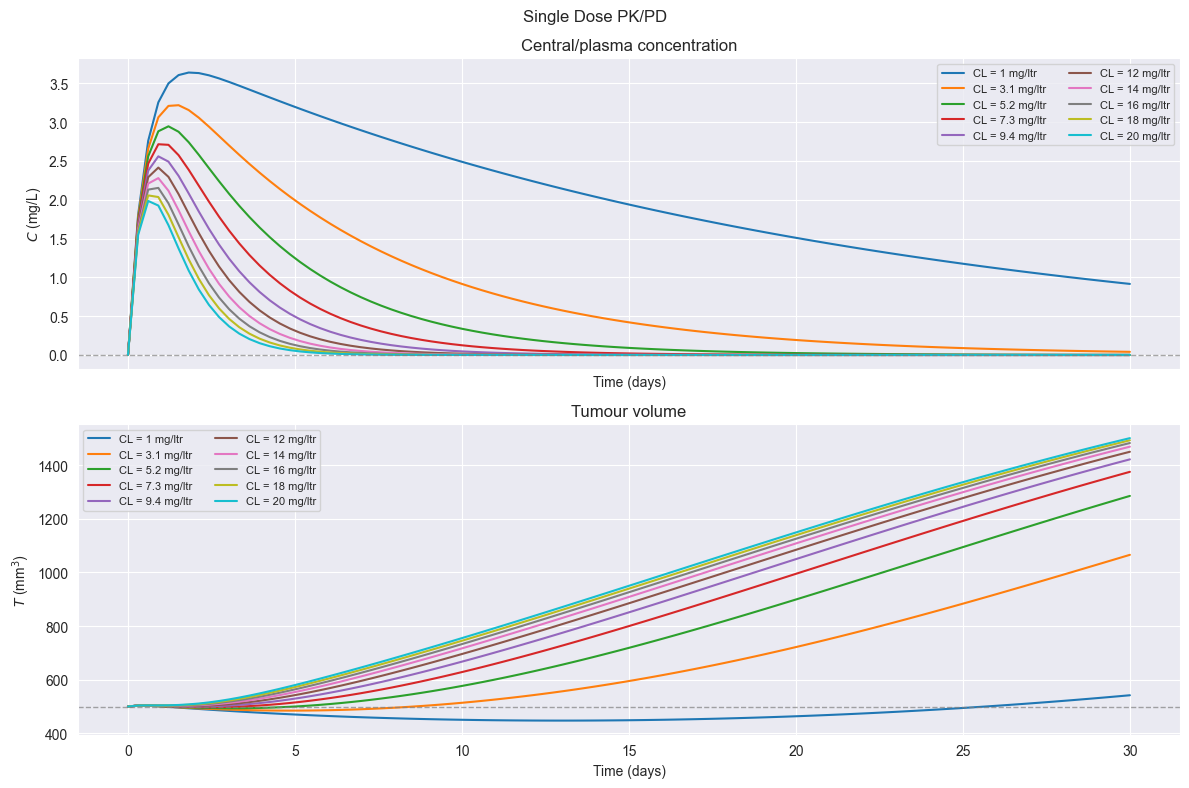

In [457]:
# Initial Condition
pill_dose = 80
T0 = 500

# Params 
kg = 2.0    
V = 20.0       
r = 0.08    
K = 2000.0       
Emax = 0.12     
EC50 = 2.0 

t_start=0
t_end=30
n_points=1000

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True)

for CL in np.linspace(1,20,10):
    theta = [kg, CL, V, r, K, Emax, EC50]
    single_dose_pkpd_plot(pill_dose, T0, t_start, t_end, n_points, theta, None, axes[0], axes[1], f"CL = {CL:.2g} mg/ltr")

axes[0].axhline(y=0,ls='--',lw=1,color='gray',alpha=0.7)
axes[0].set_ylabel(r"$C$ (mg/L)")
axes[0].set_title("Central/plasma concentration")

axes[1].axhline(y=T0,ls='--',lw=1,color='gray',alpha=0.7)
axes[1].set_ylabel(r"$T$ (mm$^3$)")
axes[1].set_title("Tumour volume")

for ax in axes:
    ax.set_xlabel("Time (days)")
    ax.tick_params('x')
    ax.legend(ncols=2, fontsize=8)

plt.suptitle('Single Dose PK/PD')
plt.tight_layout()
plt.show()

We find, keeping all other parameters fixed,
- Systems with larger clearance are flushed out of the central compartment faster, reach peak earlier and the peak concentration value is smaller.
- For clearance values above a critical threshold, the tumor never shrinks (see curves for $\text{CL} \geq 5.2 \text{mg}/\text{ltr}$). The shrinking effect is more pronounced for lower values of $\text{CL}$.

We choose a responsive regime of $\text{CL}=4 \text{mg}/\text{ltr}$. Let us next consider varying tumor growth rate $r$.

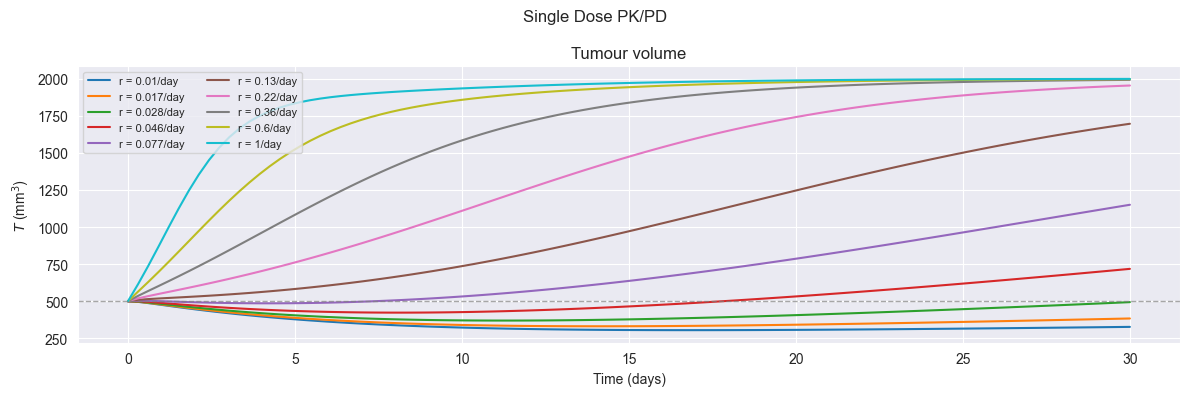

In [461]:
# Initial Condition
pill_dose = 80
T0 = 500

# Params 
kg = 2.0  
CL = 4
V = 20.0          
K = 2000.0       
Emax = 0.12     
EC50 = 2.0 

t_start=0
t_end=30
n_points=1000

fig, axes = plt.subplots(figsize=(12, 4), sharex=True)

for r in np.logspace(-2,0,10):
    theta = [kg, CL, V, r, K, Emax, EC50]
    single_dose_pkpd_plot(pill_dose, T0, t_start, t_end, n_points, theta, None, None, axes, f"r = {r:.2g}/day")

axes.axhline(y=T0,ls='--',lw=1,color='gray',alpha=0.7)
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_title("Tumour volume")

axes.set_xlabel("Time (days)")
axes.tick_params('x')
axes.legend(ncols=2, fontsize=8)

plt.suptitle('Single Dose PK/PD')
plt.tight_layout()
plt.show()

The graph above is quite intuitive. 
- For large tumor growth rates, the tumor grows faster and reaches the carrying capacity earlier.
- Above a certain growth rate, the tumor never shrinks in response to the drug (see curves for $r \geq 0.13 /\text{day}$).

Again, to remain in the responsive region, we choose $r=0.03$. Let us now inspect the influence of carrying capacity $K$.

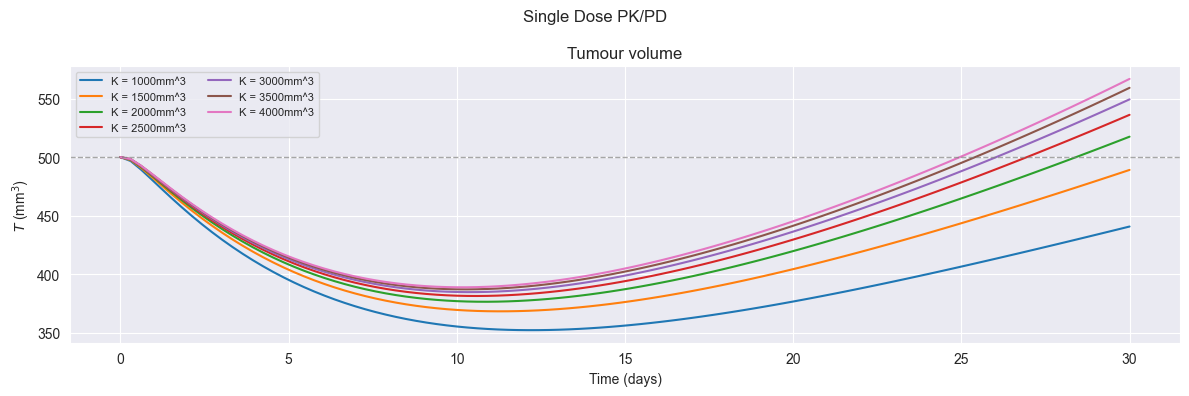

In [464]:
# Initial Condition
pill_dose = 80
T0 = 500

# Params 
kg = 2.0  
CL = 4
r=0.03
V = 20.0                
Emax = 0.12     
EC50 = 2.0 

t_start=0
t_end=30
n_points=1000

fig, axes = plt.subplots(figsize=(12, 4), sharex=True)

for K in np.arange(1000,4002,500):
    theta = [kg, CL, V, r, K, Emax, EC50]
    single_dose_pkpd_plot(pill_dose, T0, t_start, t_end, n_points, theta, None, None, axes, f"K = {K}mm^3")

axes.axhline(y=T0,ls='--',lw=1,color='gray',alpha=0.7)
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_title("Tumour volume")

axes.set_xlabel("Time (days)")
axes.tick_params('x')
axes.legend(ncols=2, fontsize=8)

plt.suptitle('Single Dose PK/PD')
plt.tight_layout()
plt.show()

The drug is found to be more effective in shrinkage for tumor-host systems with smaller $K$. For larger $K$, the drug inhibition wears off faster after treatment, i.e. the tumor starts growing back earlier, and the growth is faster.

We choose a representative value of $K=2000 \text{mm}^3$ and proceed with further inspection of $E_{max}$.

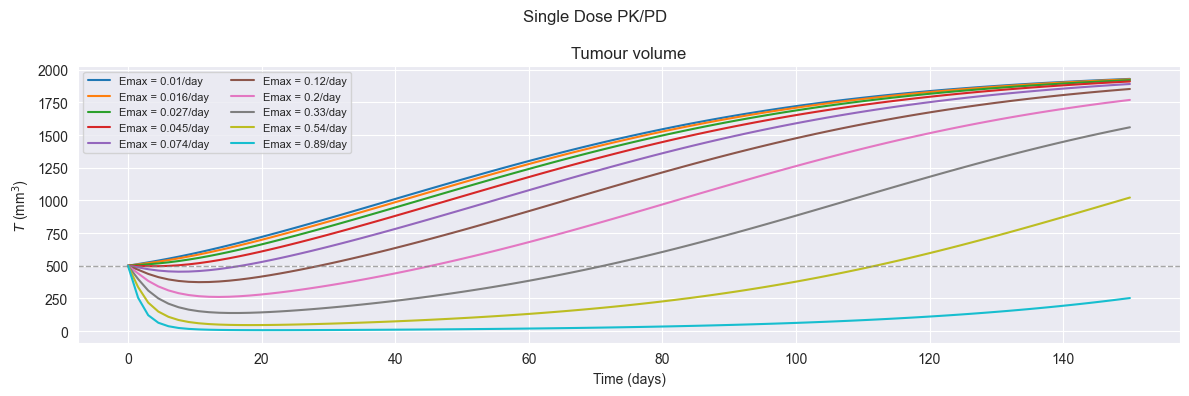

In [478]:
# Initial Condition
pill_dose = 80
T0 = 500

# Params 
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0                    
EC50 = 2.0 

t_start=0
t_end=150
n_points=1000

fig, axes = plt.subplots(figsize=(12, 4), sharex=True)

for Emax in np.logspace(-2,-0.05,10):
    theta = [kg, CL, V, r, K, Emax, EC50]
    single_dose_pkpd_plot(pill_dose, T0, t_start, t_end, n_points, theta, None, None, axes, f"Emax = {Emax:.2g}/day")

axes.axhline(y=T0,ls='--',lw=1,color='gray',alpha=0.7)
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_title("Tumour volume")

axes.set_xlabel("Time (days)")
axes.tick_params('x')
axes.legend(ncols=2, fontsize=8)

plt.suptitle('Single Dose PK/PD')
plt.tight_layout()
plt.show()

The graph above is intuitive : the parameter $E_{max}$ represents the drug's inhibition effect saturation strength. Thus reducing it results in faster rate of growth of tumor, and less shrinkage of the tumor. Below a threshold value, the tumor does not shrink at all throughout its evolution (see curves for $E_{max} \leq 0.045/\text{day}$). 

The plot above also demonstrates a nice feature : no matter how small the tumor shrinks the size to, it will always grow back in the absence of further doses. 

We select $E_{max}=0.12/\text{day}$ and further inspect influence of $EC_{50}$.

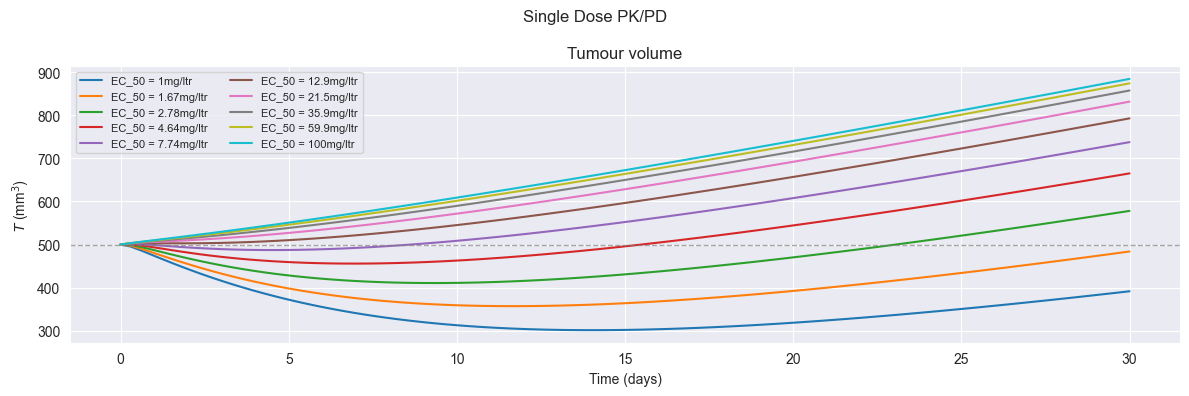

In [486]:
# Initial Condition
pill_dose = 80
T0 = 500

# Params 
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0  
Emax = 0.12

t_start=0
t_end=30
n_points=1000

fig, axes = plt.subplots(figsize=(12, 4), sharex=True)

for EC50 in np.logspace(0,2,10):
    theta = [kg, CL, V, r, K, Emax, EC50]
    single_dose_pkpd_plot(pill_dose, T0, t_start, t_end, n_points, theta, None, None, axes, f"EC_50 = {EC50:.3g}mg/ltr")

axes.axhline(y=T0,ls='--',lw=1,color='gray',alpha=0.7)
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_title("Tumour volume")

axes.set_xlabel("Time (days)")
axes.tick_params('x')
axes.legend(ncols=2, fontsize=8)

plt.suptitle('Single Dose PK/PD')
plt.tight_layout()
plt.show()

For larger values of $EC_{50}$, the drug concentration required to reach $50\%$ of max inhibition is larger. Beyond a threshold the tumor does not shrink at all and keeps growing (see curves for $EC_{50} \geq 12.9 \text{mg}/\text{ltr}$). For smaller values, the tumor temporarily shrinks further and faster.

Thus we find even with this simple model, relatively rich pharmacokinetics and pharmacodynamics.

### Visualizing effect of repeated dose

Let us now explore the tumor dynamics in the presence of multiple doses. We will consider one pill daily with varying pill quantity. We will also consider doses involving pills of 50 mg taken once daily, once in 3 days and once in a week.

In [525]:
def pkpd_sol_repeat(pill_dose, Ag_0, Ac_0, T0, t_start, t_end, n_points, theta):
    # initial conditions
    y0 = [Ag_0, Ac_0, T0]
    t_eval = np.linspace(t_start, t_end, n_points)
    
    sol = solve_ivp(pkpd_ode,(t_start, t_end), y0, t_eval=t_eval, args=(theta,))

    return sol

In [526]:
def pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval):
    Ag_0 = pill_dose
    Ac_0 = 0
    #kg, CL, V, r, K, Emax, EC50 = theta
    time_int = np.array([])
    Ag_int = np.array([])
    Ac_int = np.array([])
    T_int = np.array([])
    
    t_start_int = np.arange(0,t_end,dose_interval)
    t_end_int = t_start_int + dose_interval
    
    for t_start, t_dose in zip(t_start_int, t_end_int):
        sol = pkpd_sol_repeat(pill_dose, Ag_0, Ac_0, T0, t_start, t_dose, n_points, theta)
        time_int = np.append(time_int, sol.t)
        Ag_int = np.append(Ag_int, sol.y[0])
        Ac_int = np.append(Ac_int, sol.y[1])
        T_int = np.append(T_int, sol.y[2])
    
        Ag_0 = Ag_int[-1] + pill_dose
        Ac_0 = Ac_int[-1]
        T0 = T_int[-1]

    return time_int, Ag_int, Ac_int, T_int

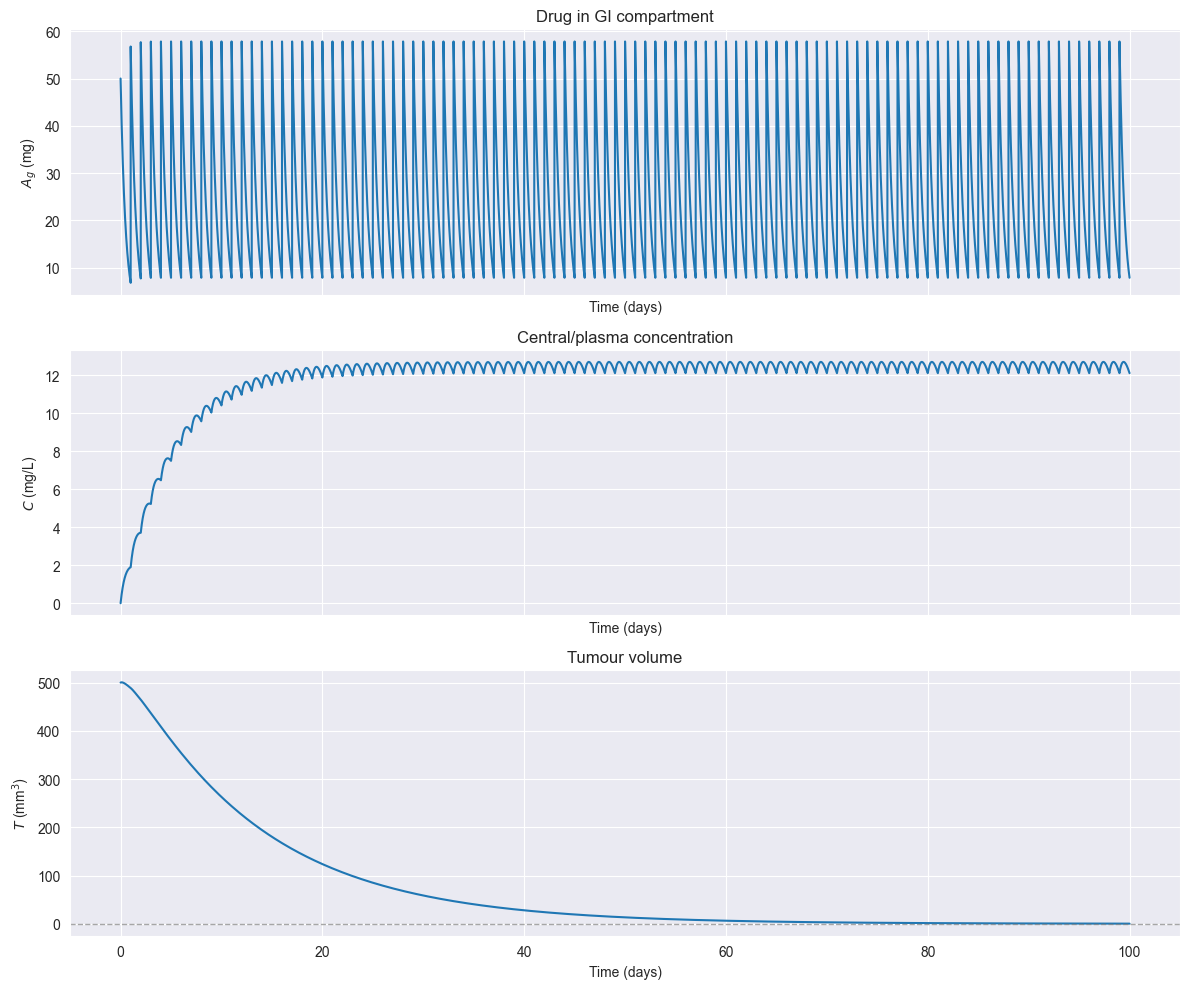

In [558]:
# Initial Condition
pill_dose = 50
T0 = 500
dose_interval = 1

# Params 
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0  
Emax = 0.12
EC50 = 2.0 

t_end = 100
n_points=100

theta = [kg, CL, V, r, K, Emax, EC50]
sol = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(sol[0], sol[1]) # amount of drug in gut compartment
axes[1].plot(sol[0], sol[2]/V) # central compartment concentration
axes[2].plot(sol[0], sol[3]) # tumor size

axes[2].axhline(y=0, color='gray', ls='--',lw=1,alpha=0.7)

axes[0].set_ylabel(r"$A_g$ (mg)")
axes[0].set_title("Drug in GI compartment")
axes[1].set_ylabel(r"$C$ (mg/L)")
axes[1].set_title("Central/plasma concentration")
axes[2].set_ylabel(r"$T$ (mm$^3$)")
axes[2].set_title("Tumour volume")

for ax in axes:
    ax.set_xlabel("Time (days)")
    ax.tick_params('x')
plt.tight_layout()
plt.show()

We find with the chosen parameters that the drug is absorbed from the gut compartment into the central compartment, following which it is cleared from the latter, and with the arrival of the next dose the concentration of the drug in the central compartment rises again. 

Also notice that the tumor dynamics appears to evolve smoothly throughout. This can be understood from considering the relatively small size of the oscillations on top of the mean value of the drug concentration profile throughout the record.

Let us explore the previous graph for one more set of parameters where the tumor does not shrink, but the growth stagnates due to the effect of the drug.

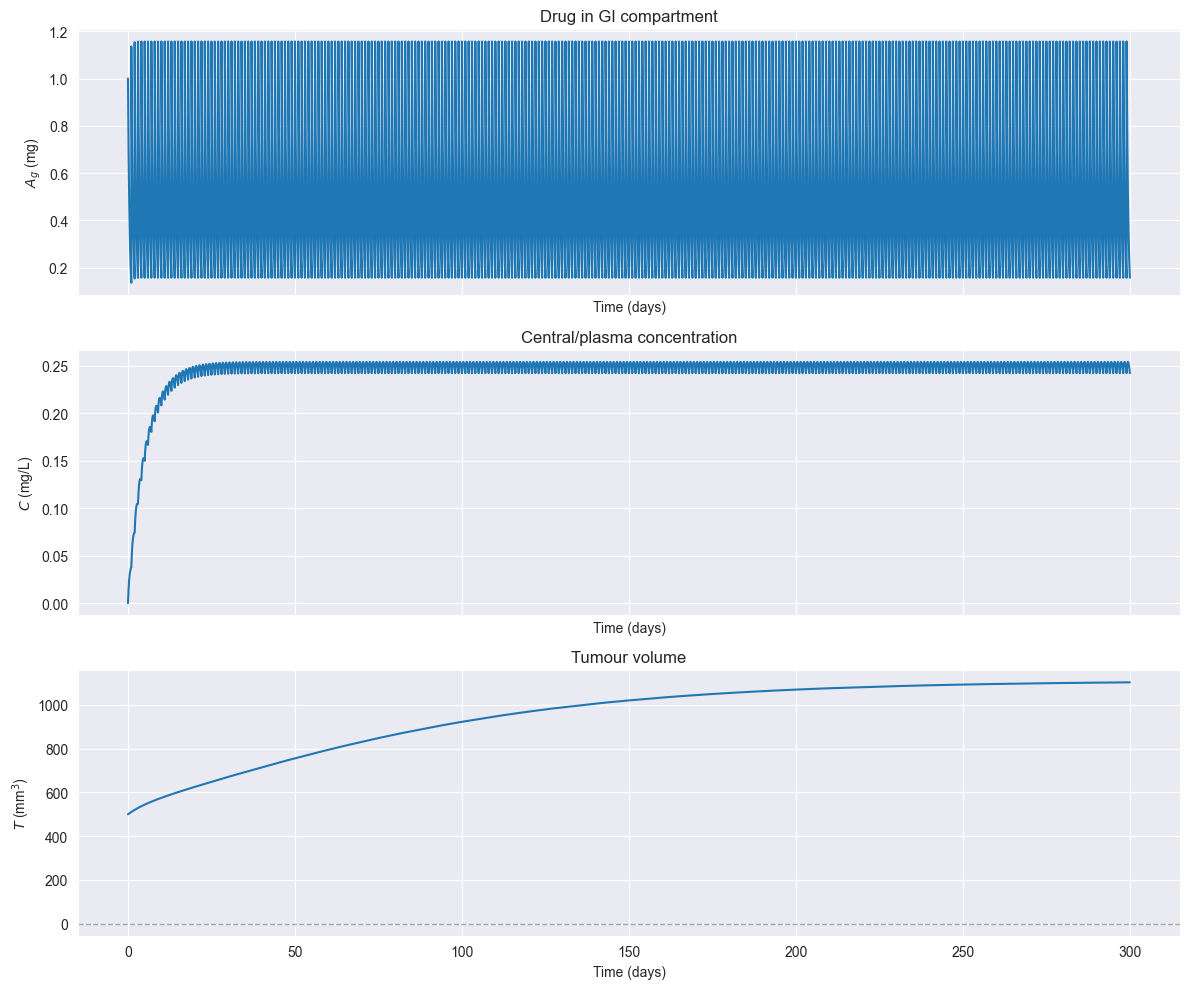

In [563]:
# Initial Condition
pill_dose = 1
T0 = 500
dose_interval = 1

# Params 
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0  
Emax = 0.12
EC50 = 2.0 

t_end = 300
n_points=100

theta = [kg, CL, V, r, K, Emax, EC50]
sol = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(sol[0], sol[1]) # amount of drug in gut compartment
axes[1].plot(sol[0], sol[2]/V) # central compartment concentration
axes[2].plot(sol[0], sol[3]) # tumor size

axes[2].axhline(y=0, color='gray', ls='--',lw=1,alpha=0.7)

axes[0].set_ylabel(r"$A_g$ (mg)")
axes[0].set_title("Drug in GI compartment")
axes[1].set_ylabel(r"$C$ (mg/L)")
axes[1].set_title("Central/plasma concentration")
axes[2].set_ylabel(r"$T$ (mm$^3$)")
axes[2].set_title("Tumour volume")

for ax in axes:
    ax.set_xlabel("Time (days)")
    ax.tick_params('x')
plt.tight_layout()
plt.show()

Notice for low doses, the tumor can settle into a positive volume long term state rather than complete eradication.

Let us now focus on the tumor dynamics and inspect the effect of varying pill dose.

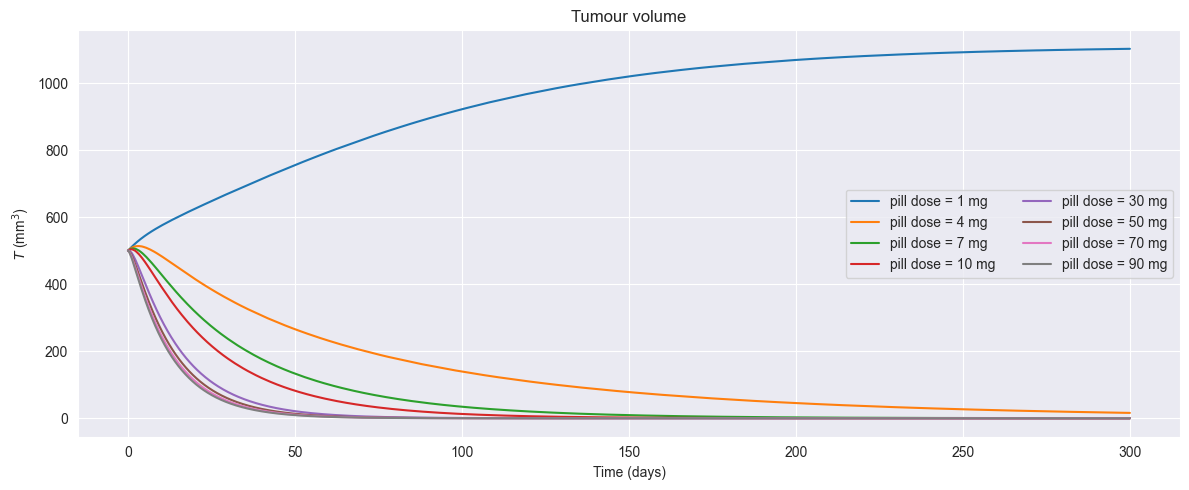

In [567]:
# Initial Condition
T0 = 500
dose_interval = 1

# Params 
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0  
Emax = 0.12
EC50 = 2.0 
theta = [kg, CL, V, r, K, Emax, EC50]

t_end = 300
n_points=100

fig, axes = plt.subplots(figsize=(12, 5), sharex=True)

for pill_dose in np.arange(1,10,3):

    sol = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
    axes.plot(sol[0], sol[3],label=f"pill dose = {pill_dose} mg") # tumor size

for pill_dose in np.arange(10,100,20):

    sol = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
    axes.plot(sol[0], sol[3],label=f"pill dose = {pill_dose} mg") # tumor size

#axes.axhline(y=K,color='gray',ls='--',lw=1,alpha=0.7)
#axes.set_xlim(100,110)
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_xlabel("Time (days)")
axes.set_title("Tumour volume")
axes.legend(ncols=2)
plt.tight_layout()
plt.show()

We find that if the pill dose is below a critical value, the tumor does not shrink and continues to grow. However, as it grows larger, its size saturates at a certain value due to a combination of drug inhibition and untreated carrying capacity $K$, giving us a state of long term positive tumor burden. 

As the dose increases, the tumor size shrinks faster but beyond a certain value, the inhibition strength saturates as a consequence of finite $EC_{50}$ in every dose.

Let us now consider pill dose of 40 mg at intervals of every day, once in 3 days, and once in a week.

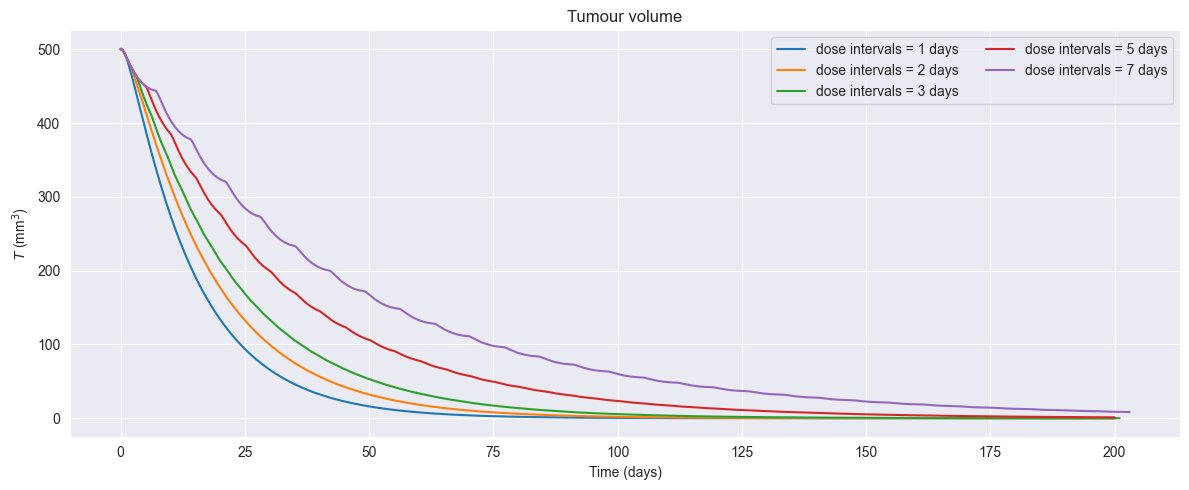

In [529]:
# Initial Condition
T0 = 500
pill_dose = 40

# Params 
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0  
Emax = 0.12
EC50 = 2.0 
theta = [kg, CL, V, r, K, Emax, EC50]

t_end = 200
n_points=100

fig, axes = plt.subplots(figsize=(12, 5), sharex=True)

for dose_interval in [1,2,3,5,7]:

    sol = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
    axes.plot(sol[0], sol[3],label=f"dose intervals = {dose_interval} days") # tumor size
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_xlabel("Time (days)")
axes.set_title("Tumour volume")
axes.legend(ncols=2)
plt.tight_layout()
plt.show()

More drug shrinks tumor faster, naturally. But let us fix the total amount of drug in a given time interval and change frequency of doses. So let us compare treatment regimen where 1. dose of 10 mg every day 2. dose of 30 mg every third day 3. dose of 50 mg every fifth day 4. dose of 70mg once a week.

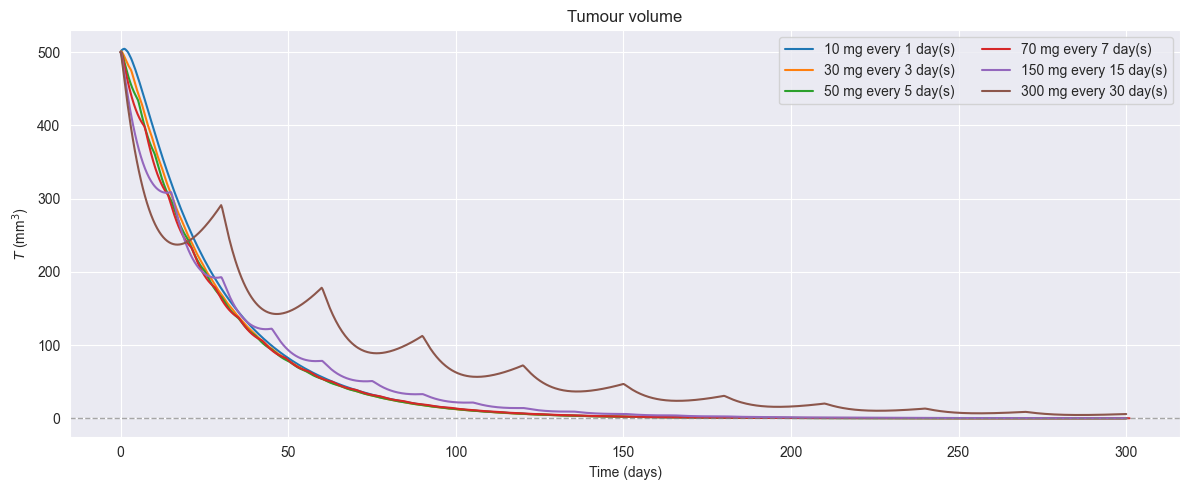

In [630]:
# Initial Condition
T0 = 500

# Params 
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0  
Emax = 0.12
EC50 = 2.0 
theta = [kg, CL, V, r, K, Emax, EC50]

t_end = 300
n_points=100

fig, axes = plt.subplots(figsize=(12, 5), sharex=True)

for (pill_dose,dose_interval) in zip([10,30,50,70, 150,300],[1,3,5,7,15,30]):

    sol = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
    axes.plot(sol[0], sol[3],label=f"{pill_dose} mg every {dose_interval} day(s)") # tumor size

axes.axhline(y=0, ls='--',lw=1, color='gray',alpha=0.7)
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_xlabel("Time (days)")
axes.set_title("Tumour volume")
axes.legend(ncols=2)
plt.tight_layout()
plt.show()

Clearly the same amount drug has different effect when administered at different doses. Higher amount of drug shrinks the tumor faster, but long durations without the drug results in the tumor going back into the growth phase. We see that for doses with modest frequency (see curves with dose frequency of every week or higher), the cancer shrinks to zero at effectively the same time.   

Note that there is no sufficiently strong treatment that can eradicate the tumor, such that treatment can eventually be stopped without relapse. The current ODE model cannot represent this phenomenon for the biologically relevant parameter space (in particular with $r>0$). In the current model, the tumor size does not reach zero in finite time, it only becomes arbitrarily small, and hence once the drug is stopped, it grows back. 

## Model Simulation and Model Fit 

In this section we will generate synthetic datasets for various doses and use these datasets for ODE model parameter estimation. 

### Synthetic data generation via PK/PD model simulation

We now generate synthetic datasets using a hidden true parameter vector $(k_g = 2 /\text{day}, CL = 4 \text{ltrs/day}, V = 20 \text{ltrs}, r=0.03/ \text{day}, K=2000 \text{mm}^3, E_{max}=0.12 /\text{day}, EC_{50}=2 \text{mg}/\text{ltr})$.

We train the models with the following dosages,
- Control Group : $0 \text{mg}/\text{day}$
- Low drug exposure : $25 \text{mg}/\text{day}$
- Medium drug exposure : $50 \text{mg}/\text{day}$
- High drug exposure : $100 \text{mg}/\text{day}$
every day, for 29 days, with the following initial tumor sizes $T_0 = (50,100,200,500) \text{mm}^3$.

We will then validate the model performance on a held out set with the dosage of $75 \text{mg}/\text{day}$ for an initial tumor size of $T_0 = 300\text{mm}^3$ to see how well the model performs on unseen data.


We plot tumor dynamics for two representative sizes below.

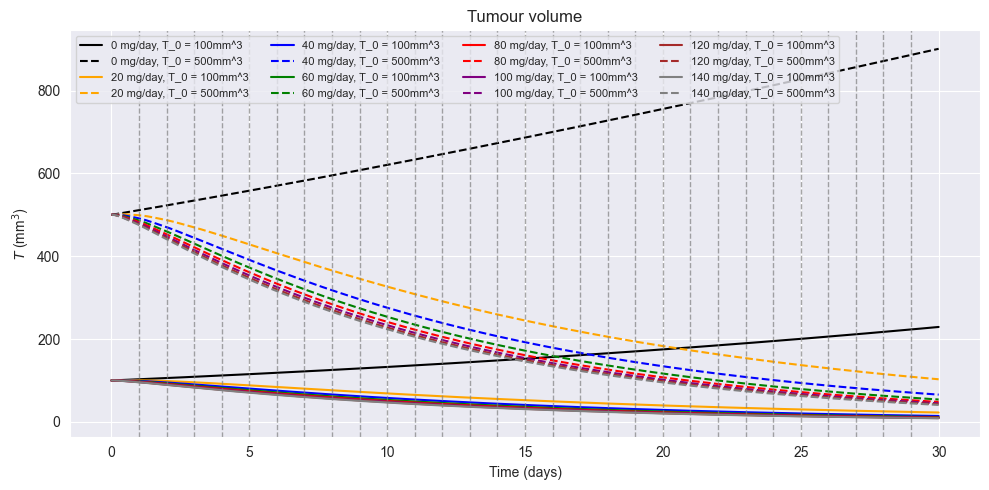

In [761]:
kg = 2.0  
CL = 4
K = 2000
r=0.03
V = 20.0  
Emax = 0.12
EC50 = 2.0 
theta = [kg, CL, V, r, K, Emax, EC50]

n_points = 500
t_end = 30
dose_interval = 1

fig, axes = plt.subplots(figsize=(10, 5), sharex=True)

graph_col = ['black', 'orange', 'blue', 'green', 'red', 'purple', 'brown', 'gray']
linestyle_list = ['-','--']
for i,pill_dose in enumerate([0,20,40, 60, 80, 100, 120, 140]):
    for j,T0 in enumerate([100,500]):

        time_int, Ag_int, Ac_int, T_int = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
        C_int = Ac_int/V
        
        axes.plot(time_int, T_int, label=f"{pill_dose} mg/day, T_0 = {T0}mm^3",ls=linestyle_list[j], color=graph_col[i])
    
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_title("Tumour volume")

for t_end_ints in np.arange(0,t_end,dose_interval)[1:]:
    axes.axvline(t_end_ints, color='gray', ls='--',lw=1,alpha=0.7)
axes.set_xlabel("Time (days)")
axes.tick_params('x')
axes.legend(ncols=4, fontsize=8)
plt.tight_layout()
plt.show()

In [762]:
calibration_set_PK = []

for pill_dose in [0,20,40, 60, 80, 100, 120, 140]:
    for T0 in [50,100,200,500]:
        Ag_0 = pill_dose

        time_int, Ag_int, Ac_int, T_int = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
        C=Ag_int/V
        for i in range(len(time_int)):
            calibration_set_PK.append({"dose(mg/day)": pill_dose,"Tumor initial size": T0,"t (days)": time_int[i],"Ag(t)": Ag_int[i],
                                       "Ac(t)": Ac_int[i], "Tumor size (t)": T_int[i], "C(t)":C[i]})

In [763]:
calibration_set_PK = pd.DataFrame(calibration_set_PK)
calibration_set_PK

,dose(mg/day),Tumor initial size,t (days),Ag(t),Ac(t),Tumor size (t),C(t)
0,0,50,0.000000,0.000000,0.000000,50.000000,0.000000
1,0,50,0.002004,0.000000,0.000000,50.002931,0.000000
2,0,50,0.004008,0.000000,0.000000,50.005862,0.000000
3,0,50,0.006012,0.000000,0.000000,50.008793,0.000000
4,0,50,0.008016,0.000000,0.000000,50.011725,0.000000
...,...,...,...,...,...,...,...
479995,140,500,29.991984,22.311928,677.182795,40.998252,1.115596
479996,140,500,29.993988,22.222714,677.000626,40.991357,1.111136
479997,140,500,29.995992,22.133848,676.818183,40.984464,1.106692
479998,140,500,29.997996,22.045328,676.635468,40.977572,1.102266


In [765]:
8*4*500*30

480000

To simulate real world data, we add noise to the synthetic dataset. Using,
\begin{align}
C_{obs} (t) = C_{true} (t) + \epsilon_C \,, T_{obs} (t) = T_{true} (t) + \epsilon_T
\end{align}
where $\epsilon_C \sim \mathcal{N}(0,\sigma^2_C)$ and $\epsilon_T \sim \mathcal{N}(0,\sigma^2_T)$ are drawn from standard normal distribution. Since the concentration $C(t)$ and tumor size are $\mathcal{O}(1) \text{mg}$ and $\mathcal{O}(10)-\mathcal{O}(100) \text{mm}^3$, let us choose $\sigma_C=0.05 \text{mg}$ and $\sigma_T = 1 \text{mm}^3$.

Let us visualize this choice for the smallest tumor size.

In [772]:
sigma_C = 0.05       # concentration noise (mg/ltr)
sigma_T = 0.5     # tumor volume noise (cubic mm)
seed = 19

rng = np.random.default_rng(seed)

calibration_set_PK["C obs"] = np.maximum(calibration_set_PK["C(t)"] + rng.normal(loc=0.0,scale=sigma_C,size=len(calibration_set_PK)),0)

calibration_set_PK["Tumor size obs"] = calibration_set_PK["Tumor size (t)"] + rng.normal(loc=0.0,scale=sigma_T,size=len(calibration_set_PK))

print(f"Negative Concentrations simulated ? : {np.any(calibration_set_PK["C obs"]<0)}")

Negative Concentrations simulated ? : False


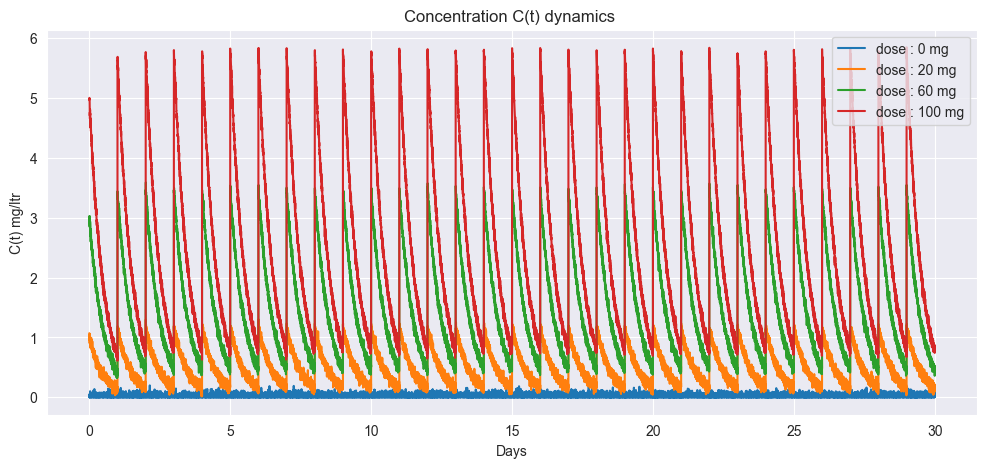

In [773]:
figure, axes = plt.subplots(figsize=(12,5))
for dose in [0,20,60,100]:
    dose_group = calibration_set_PK[(calibration_set_PK['dose(mg/day)']==dose)&(calibration_set_PK['Tumor initial size']==50)]
    axes.plot(dose_group['t (days)'], dose_group['C obs'],label=f'dose : {dose} mg')

axes.set_xlabel('Days')
axes.set_ylabel('C(t) mg/ltr')
axes.set_title('Concentration C(t) dynamics ')
axes.legend()
plt.show()

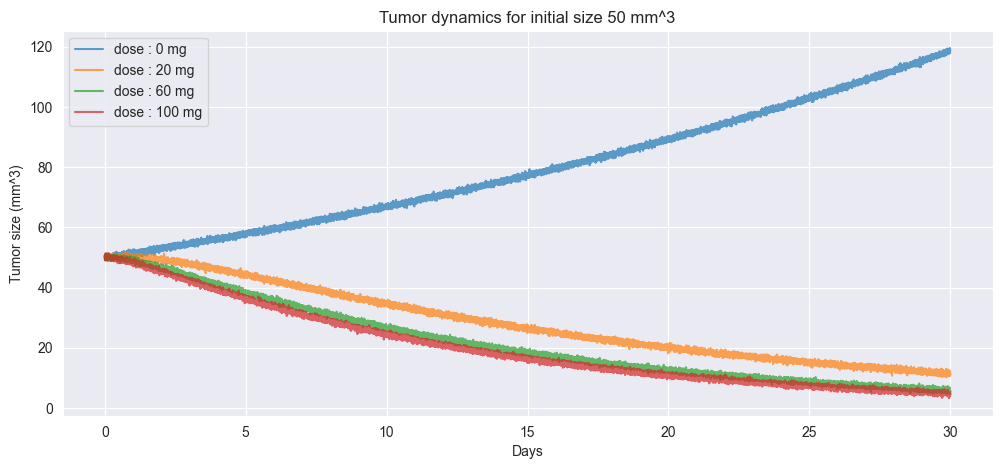

In [775]:
figure, axes = plt.subplots(figsize=(12,5))
for dose in [0,20,60,100]:
    dose_group = calibration_set_PK[(calibration_set_PK['dose(mg/day)']==dose)&(calibration_set_PK['Tumor initial size']==50)]
    axes.plot(dose_group['t (days)'], dose_group['Tumor size obs'],label=f'dose : {dose} mg',alpha=0.7)

axes.set_xlabel('Days')
axes.set_ylabel('Tumor size (mm^3)')
axes.set_title('Tumor dynamics for initial size 50 mm^3')
axes.legend()
plt.show()

Generated synthetic dataset has reasonable level of noise. 

Let us now store the validation dataset.

In [776]:
n_points=500
t_end = 30
val_set_PK = []

pill_dose = 75
T0 = 300
time_int, Ag_int, Ac_int, T_int = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
C=Ag_int/V
for i in range(len(time_int)):
    val_set_PK.append({"dose(mg/day)": pill_dose,"Tumor initial size": T0,"t (days)": time_int[i],"Ag(t)": Ag_int[i],
                               "Ac(t)": Ac_int[i], "Tumor size (t)": T_int[i], "C(t)":C[i]})

val_set_PK = pd.DataFrame(val_set_PK)
val_set_PK["C obs"] = np.maximum(val_set_PK["C(t)"] + rng.normal(loc=0.0,scale=sigma_C,size=len(val_set_PK)),0)

val_set_PK["Tumor size obs"] = val_set_PK["Tumor size (t)"] + rng.normal(loc=0.0,scale=sigma_T,size=len(val_set_PK))

print(f"Negative Concentrations simulated ? : {np.any(val_set_PK["C obs"]<0)}")

Negative Concentrations simulated ? : False


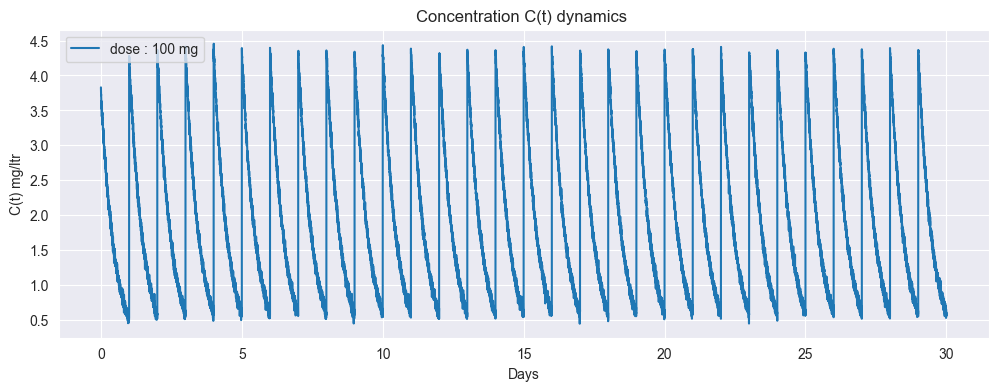

In [777]:
figure, axes = plt.subplots(figsize=(12,4))
axes.plot(val_set_PK['t (days)'], val_set_PK['C obs'],label=f'dose : {dose} mg')

axes.set_xlabel('Days')
axes.set_ylabel('C(t) mg/ltr')
axes.set_title('Concentration C(t) dynamics ')
axes.legend()
plt.show()

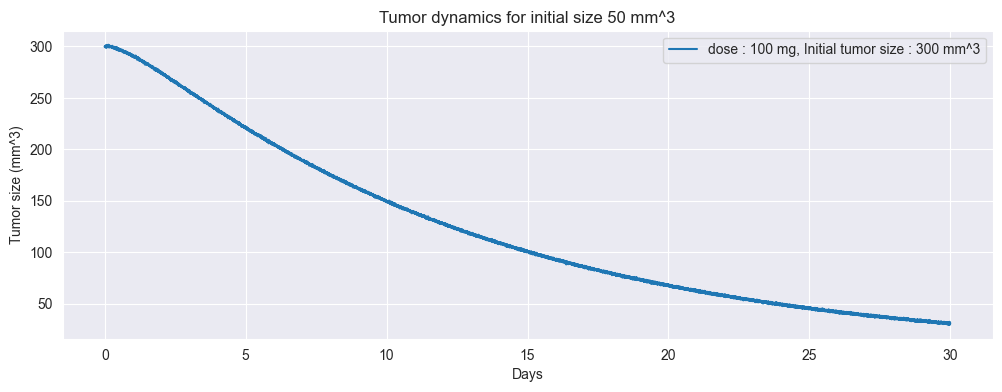

In [778]:
figure, axes = plt.subplots(figsize=(12,4))
axes.plot(val_set_PK['t (days)'], val_set_PK['Tumor size obs'],label=f'dose : {dose} mg, Initial tumor size : {T0} mm^3')

axes.set_xlabel('Days')
axes.set_ylabel('Tumor size (mm^3)')
axes.set_title('Tumor dynamics for initial size 50 mm^3')
axes.legend()
plt.show()

We will now fit ODE models on this dataset.

### Model Fitting

We will now fit ODE models on the synthetic training data. We will use two optimizers : Powell as the representative non-gradient search, and BFGS as the representative gradient search optimizer. We will also consider optimization of log-scaled params, in addition to optimization over scaled params. To investigate the effect of initial values, we will consider two sets of initializers, one of which is not very challenging since it is close to the true params,
- (kg, CL, V, r, K, Emax, EC50) = `np.array([ 1.0, 4.0, 15.0, 0.05, 1500.0, 0.10, 1.0])`
the other comparatively challenging, further away from the true params,
- (kg, CL, V, r, K, Emax, EC50) = `np.array([ 2.9, 6.0, 29.0, 0.02, 2999.0, 0.20, 4.0]) `

For every dose and initial tumor size, we will have to obtain the model predictions separately for candidate parameter vector $\theta$.

In [779]:
df_train = calibration_set_PK[['dose(mg/day)','Tumor initial size','C obs','Tumor size obs']]

In [786]:
def log_likelihood(C_obs, T_obs, C_pred, T_pred):

    residual_C = C_obs - C_pred
    residual_T = T_obs - T_pred

    RSS_C = np.sum(residual_C**2)
    RSS_T = np.sum(residual_T**2)

    N_C = len(residual_C)
    N_T = len(residual_T)

    log_like = (N_C * np.log(RSS_C / N_C)+ N_T * np.log(RSS_T / N_T))

    return log_like

In [787]:
def objective(theta, df_train):
    global call_count
    call_count+=1
    
    log_like = 0
    
    Ac_0 = 0
    n_points = 500
    t_end = 30
    dose_interval =1 
    df_train_grouped = df_train.groupby(["dose(mg/day)", "Tumor initial size"],sort=False)
    
    for (pill_dose, T0), _ in df_train_grouped.groups.items():
        Ag_0 = pill_dose
        _, _, Ac_pred, T_pred = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
        C_pred = Ac_pred/theta[2]

        C_obs = df_train[(df_train['dose(mg/day)']==pill_dose)&(df_train['Tumor initial size']==T0)]['C obs'].values
        T_obs = df_train[(df_train['dose(mg/day)']==pill_dose)&(df_train['Tumor initial size']==T0)]['Tumor size obs'].values
        log_like+=log_likelihood(C_obs, T_obs, C_pred, T_pred)

    if call_count % 100 == 0:
        print(f"\r Evaluation {call_count}, objective = {log_like:.4f}, theta = {theta}", end="", flush=True)
        
    return log_like

In [788]:
def objective_log(phi, df_train):

    theta = np.exp(phi)

    return objective(theta, df_train)

In [792]:
def objective_optimizer(initializer, df_train, bounds, objective_func, method_optimize, output_list):
    if method_optimize == "Powell":
        options = {"maxiter": 300, "maxfev": 3000,"xtol": 1e-3,"ftol": 1e-3}

    elif method_optimize == "L-BFGS-B":
        options = {"maxiter": 300,"gtol": 1e-3,"ftol": 1e-5}

    if (objective_func==objective):
        t0 = time.time()
        result = minimize(objective_func, x0 = initializer, args=(df_train,),method=method_optimize,bounds=bounds,
                      options=options)
        optimization_time = time.time() - t0
        output_list.append({"Log Scaled Params":"No", "method_optimize":method_optimize, "initializer":initializer,
                       "Time":optimization_time,"Status":result.success, "Objective":result.fun, "Est Params":result.x,
                           "Optimizer Iterations":result.nit, "Objective func iterations":result.nfev})
    elif (objective_func==objective_log):
        t0 = time.time()
        result = minimize(objective_func, x0 = np.log(initializer), args=(df_train,),method=method_optimize,bounds=np.log(np.array(bounds)),
                      options=options)
        optimization_time = time.time() - t0
        output_list.append({"Log Scaled Params":"Yes", "method_optimize":method_optimize, "initializer":initializer,
                       "Time":optimization_time,"Status":result.success, "Objective":result.fun, "Est Params":np.exp(result.x),
                           "Optimizer Iterations":result.nit, "Objective func iterations":result.nfev})

    return output_list

In [790]:
output_list=[]

Initializer 1, Powell, Non scaled params :

In [793]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 1.0, 4.0, 15.0, 0.05, 1500.0, 0.10, 1.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective, "Powell", output_list)

 Evaluation 100, objective = 2431382.5771, theta = [2.99963328e+00 9.99940504e+00 1.00004837e+01 1.76115675e-02
 Evaluation 200, objective = 2162644.3114, theta = [8.21119592e-01 9.80607375e+00 1.06467272e+01 1.76224194e-02
 Evaluation 300, objective = 1822957.8483, theta = [5.50169351e-01 9.99940504e+00 1.43886346e+01 1.75920811e-02
 Evaluation 400, objective = 1580539.6494, theta = [5.00000255e-01 9.99940504e+00 1.86419453e+01 1.76103266e-02
 Evaluation 500, objective = 1483088.1265, theta = [5.00138114e-01 9.99942482e+00 1.89779707e+01 1.76126447e-02
 Evaluation 600, objective = 1446321.1367, theta = [5.02559957e-01 9.99977272e+00 1.93154940e+01 1.76142549e-02
 Evaluation 700, objective = 1410365.1035, theta = [5.00135673e-01 9.99999990e+00 1.94974566e+01 1.76141242e-02
 Evaluation 800, objective = 1385361.4601, theta = [5.00135673e-01 9.99999992e+00 1.99932993e+01 1.76175842e-02
 Evaluation 900, objective = 1383635.9126, theta = [5.00000421e-01 9.99959421e+00 1.99938839e+01 1.76197

Initializer 1, Powell, Log scaled params :

In [794]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 1.0, 4.0, 15.0, 0.05, 1500.0, 0.10, 1.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective_log, "Powell", output_list)

 Evaluation 100, objective = 2387208.4921, theta = [2.99856483e+00 9.99355407e+00 1.00047221e+01 1.74516162e-02
 Evaluation 200, objective = 2126474.8430, theta = [8.45586701e-01 9.99924166e+00 1.06098978e+01 1.70146399e-02
 Evaluation 300, objective = 2120180.4921, theta = [8.46072589e-01 9.99355407e+00 2.07297415e+01 1.70133174e-02
 Evaluation 400, objective = 1474914.5367, theta = [5.00226123e-01 9.98957234e+00 2.12380521e+01 1.68270764e-02
 Evaluation 500, objective = 1445027.1382, theta = [5.00386760e-01 9.99999984e+00 2.16897816e+01 1.68144602e-02
 Evaluation 600, objective = 1406924.2435, theta = [5.00000103e-01 9.99355778e+00 2.31466532e+01 1.68159069e-02
 Evaluation 700, objective = 1363237.1142, theta = [5.25901374e-01 9.99330180e+00 2.55570194e+01 1.68029725e-02
 Evaluation 800, objective = 3870255.5941, theta = [6.73606232e-01 9.99270758e+00 2.83473087e+01 1.68327224e-02
 Evaluation 900, objective = 1209675.2845, theta = [7.09517763e-01 9.99358650e+00 2.86257889e+01 1.68228

Initializer 1, BFGS, Non scaled params :

In [795]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 1.0, 4.0, 15.0, 0.05, 1500.0, 0.10, 1.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective, "L-BFGS-B", output_list)

 Evaluation 100, objective = 2935926.6559, theta = [1.36326098e+00 5.09239841e+00 1.40914207e+01 4.11586888e-02
 Evaluation 200, objective = 2671422.5100, theta = [1.77107887e+00 6.31312583e+00 1.30721542e+01 3.09865950e-02
 Evaluation 300, objective = 2313326.9832, theta = [2.91637967e+00 1.00000000e+01 1.00929368e+01 2.91512246e-02
 Evaluation 400, objective = 2152059.9394, theta = [2.76851143e+00 9.58320421e+00 1.04501671e+01 3.11586981e-02
 Evaluation 500, objective = 2176864.7437, theta = [2.76427381e+00 9.60069667e+00 1.04351672e+01 3.01842549e-02
 Evaluation 600, objective = 1840740.9672, theta = [2.75573668e+00 9.59066794e+00 1.04503556e+01 2.99551030e-02
 Evaluation 700, objective = 1796634.9931, theta = [2.81662990e+00 1.00000000e+01 1.01757107e+01 2.99916283e-02
 2.00076665e+03 1.18208808e-01 1.27176144e+00]

Initializer 1, BFGS, Log scaled params :

In [796]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 1.0, 4.0, 15.0, 0.05, 1500.0, 0.10, 1.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective_log, "L-BFGS-B", output_list)

 Evaluation 100, objective = 2334150.3577, theta = [8.13225645e-01 1.00000000e+01 2.32057940e+01 4.84185468e-02
 Evaluation 200, objective = 1694200.0236, theta = [5.67682283e-01 1.00000000e+01 3.00000000e+01 2.58597821e-02
 Evaluation 300, objective = 1806356.1657, theta = [7.22707140e-01 1.00000000e+01 2.12360241e+01 2.93740280e-02
 Evaluation 400, objective = 512545.7757, theta = [6.76946429e-01 1.00000000e+01 2.31566301e+01 2.99989545e-02
 Evaluation 500, objective = 461118.0686, theta = [9.15545634e-01 1.00000000e+01 2.99999997e+01 2.99601942e-02
 2.00875616e+03 1.20361043e-01 8.87668222e-01]

In [797]:
pd.DataFrame(output_list)

,Log Scaled Params,method_optimize,initializer,Time,Status,Objective,Est Params,Optimizer Iterations,Objective func iterations
0,No,Powell,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",1197.080658,True,1.105104e+06,"[0.5198626947804558, 9.999229746170169, 18.371...",14,1605
1,Yes,Powell,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",1083.282440,True,1.045991e+06,"[0.9322711080389946, 9.993180470946344, 29.999...",12,1479
2,No,L-BFGS-B,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",651.267025,True,1.792796e+06,"[2.8187606606249527, 10.0, 10.177706123938957,...",47,728
3,Yes,L-BFGS-B,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",412.089098,True,4.393202e+05,"[0.9428781717041373, 10.000000000000002, 30.00...",45,576


In [ ]:
del output_list[-1]

Initializer 2, Powell, Non scaled params :

In [ ]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 2.9, 6.0, 29.0, 0.02, 2999.0, 0.20, 4.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective, "Powell", output_list)

Initializer 2, Powell, Log scaled params :

In [ ]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 2.9, 6.0, 29.0, 0.02, 2999.0, 0.20, 4.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective_log, "Powell", output_list)

Initializer 2, BFGS, Non scaled params :

In [ ]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 2.9, 6.0, 29.0, 0.02, 2999.0, 0.20, 4.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective, "L-BFGS-B", output_list)

Initializer 2, BFGS, Log scaled params :

In [ ]:
# Intializer (kg, CL, V, r, K, Emax, EC50)
theta0 = np.array([ 2.9, 6.0, 29.0, 0.02, 2999.0, 0.20, 4.0]) 

# Bounds (kg, CL, V, r, K, Emax, EC50)
bounds = [(0.5, 3.0), (1, 10.0), (10.0, 30.0), (0.01, 0.2), (500.0, 3000.0), (0.09, 0.4), (0.1, 10.0)]

call_count = 0
output_list = objective_optimizer(theta0, df_train, bounds, objective_log, "L-BFGS-B", output_list)

Let us now compare the optimizers using the error between true parameters and estimated parameters, as well as compare their performance on the held out validation set, with tumor size of $300 \text{mm}^3$ and dose of $75\text{mg}/\text{day}$.

### Parameter Recovery Scoring

Let us consider the parameter wise absolute relative error,
\begin{align}
\text{Rel Error}_i = \frac{| \hat{\theta}_i - \theta_i^{true} |}{\theta_i^{true}}
\end{align}
for the $i$-th parameter, and $\hat{}$ represents estimated parameter. We will also monitor the mean relative error, which represents the overall error made by an optimizer in parameter estimation,
\begin{align}
\text{Mean Rel Error}_i = \frac{1}{N} \sum_i \frac{| \hat{\theta}_i - \theta_i^{true} |}{\theta_i^{true}}
\end{align}
where the number of parameters $N=7$, as well as the log error, which is more appropriate since the different parameters in this model have different scales,
\begin{align}
\text{Log Error}_i = | \log \left( \frac{\hat{\theta}_i}{\theta_i^{true}} \right) | \,, \qquad \text{Mean Log Error} = \frac{1}{N} \sum_i \text{Log Error}_i 
\end{align}

In [798]:
optimize_result_df = pd.DataFrame(output_list)
theta_true = np.array([2.0, 4, 20, 0.03, 2000, 0.12, 2])

optimize_result_df["Rel Error"] = None
optimize_result_df["Abs Log Error"] = None

In [799]:
for i in range(len(optimize_result_df)):
    theta_est = np.array(optimize_result_df.loc[i,'Est Params'])
    
    rel_error = np.abs(theta_est - theta_true) / theta_true
    abs_log_error = np.abs(np.log(theta_est / theta_true))

    optimize_result_df.at[i, 'Rel Error'] = rel_error
    optimize_result_df.at[i, 'Mean Rel Error'] = np.mean(rel_error)

    optimize_result_df.at[i, 'Abs Log Error'] = abs_log_error
    optimize_result_df.at[i, 'Mean Abs Log Error'] = np.mean(abs_log_error)

In [800]:
optimize_result_df

,Log Scaled Params,method_optimize,initializer,Time,Status,Objective,Est Params,Optimizer Iterations,Objective func iterations,Rel Error,Abs Log Error,Mean Rel Error,Mean Abs Log Error
0,No,Powell,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",1197.080658,True,1.105104e+06,"[0.5198626947804558, 9.999229746170169, 18.371...",14,1605,"[0.7400686526097722, 1.4998074365425422, 0.081...","[1.3473377313326755, 0.9162137035245648, 0.084...",0.523754,0.581194
1,Yes,Powell,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",1083.282440,True,1.045991e+06,"[0.9322711080389946, 9.993180470946344, 29.999...",12,1479,"[0.5338644459805026, 1.498295117736586, 0.4999...","[0.7632787987024777, 0.9156085463331365, 0.405...",0.562903,0.558433
2,No,L-BFGS-B,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",651.267025,True,1.792796e+06,"[2.8187606606249527, 10.0, 10.177706123938957,...",47,728,"[0.40938033031247634, 1.5, 0.4911146938030521,...","[0.3431501257416487, 0.9162907318741551, 0.675...",0.403636,0.353063
3,Yes,L-BFGS-B,"[1.0, 4.0, 15.0, 0.05, 1500.0, 0.1, 1.0]",412.089098,True,4.393202e+05,"[0.9428781717041373, 10.000000000000002, 30.00...",45,576,"[0.5285609141479313, 1.5000000000000004, 0.500...","[0.7519653775090243, 0.9162907318741552, 0.405...",0.440471,0.411387


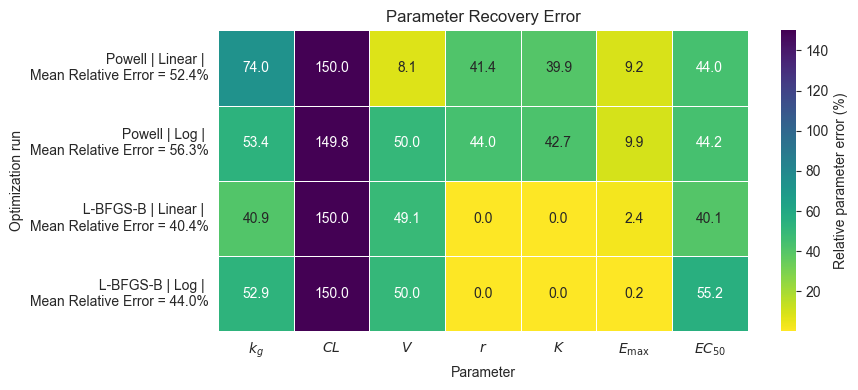

In [833]:
# Parameter names
param_names = [
    r"$k_g$", r"$CL$", r"$V$", r"$r$", 
    r"$K$", r"$E_{\max}$", r"$EC_{50}$"
]

# Convert the list/array in 'Rel Error' into a matrix
error_matrix = np.vstack(optimize_result_df["Rel Error"].values) * 100

# Create labels for each optimization run
run_labels = []

for _, row in optimize_result_df.iterrows():
    init = np.array(row["initializer"])
    method = row["method_optimize"]
    log_scaled = row["Log Scaled Params"]

    # Identify initializer
    if np.allclose(init, np.array([ 1.0, 4.0, 15.0, 0.05, 1500.0, 0.10, 1.0])):
        init_label = "Init 1"
    elif np.allclose(init, np.array([ 2.9, 6.0, 29.0, 0.02, 2999.0, 0.20, 4.0]) ):
        init_label = "Init 2"

    log_label = "Log" if log_scaled == "Yes" else "Linear"

    mean_error = row["Mean Rel Error"] * 100

    run_labels.append(
        f" {method} | {log_label} | \nMean Relative Error = {mean_error:.1f}%"
    )

    # dropped init_label. restore for multiple initializers

# Put errors into a DataFrame
error_df = pd.DataFrame(
    error_matrix,
    index=run_labels,
    columns=param_names
)

# Plot
plt.figure(figsize=(9, 4))

sns.heatmap(
    error_df,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cmap="viridis_r",
    cbar_kws={"label": "Relative parameter error (%)"}
)

plt.xlabel("Parameter")
plt.ylabel("Optimization run")
plt.title("Parameter Recovery Error")
plt.tight_layout()
plt.show()

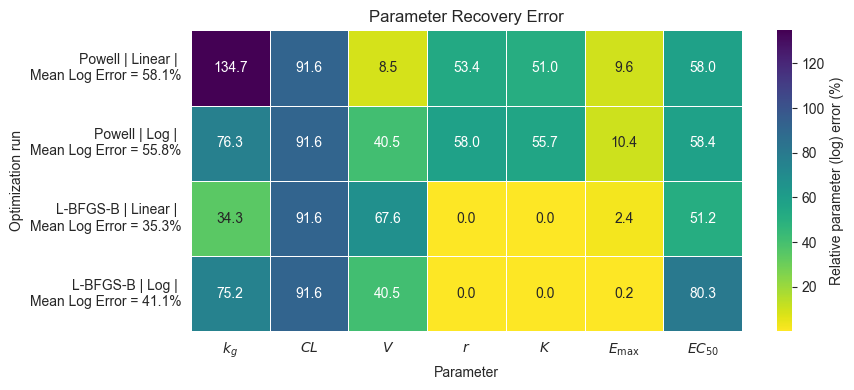

In [834]:
# Parameter names
param_names = [
    r"$k_g$", r"$CL$", r"$V$", r"$r$", 
    r"$K$", r"$E_{\max}$", r"$EC_{50}$"
]

# Convert the list/array in 'Rel Error' into a matrix
error_matrix = np.vstack(optimize_result_df["Abs Log Error"].values) * 100

# Create labels for each optimization run
run_labels = []

for _, row in optimize_result_df.iterrows():
    init = np.array(row["initializer"])
    method = row["method_optimize"]
    log_scaled = row["Log Scaled Params"]

    # Identify initializer
    if np.allclose(init, np.array([ 1.0, 4.0, 15.0, 0.05, 1500.0, 0.10, 1.0])):
        init_label = "Init 1"
    elif np.allclose(init, np.array([ 2.9, 6.0, 29.0, 0.02, 2999.0, 0.20, 4.0]) ):
        init_label = "Init 2"

    log_label = "Log" if log_scaled == "Yes" else "Linear"

    mean_error = row["Mean Abs Log Error"] * 100

    run_labels.append(
        f"{method} | {log_label} | \nMean Log Error = {mean_error:.1f}%"
    )
    # dropped init_label. restore for multiple initializers

# Put errors into a DataFrame
error_df = pd.DataFrame(
    error_matrix,
    index=run_labels,
    columns=param_names
)

# Plot
plt.figure(figsize=(9, 4))

sns.heatmap(
    error_df,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cmap="viridis_r",
    cbar_kws={"label": "Relative parameter (log) error (%)"}
)

plt.xlabel("Parameter")
plt.ylabel("Optimization run")
plt.title("Parameter Recovery Error")
plt.tight_layout()
plt.show()

We find Powell optimizer to have a mean parameter recovery relative error rate of $52.4\%$ and $56.3\%$, and relative log error rate of $58.1\%$ and $55.8\%$ respectively for non-scaled and log-scaled parameters. The error rates improve significantly for BFGS optimizer, which has a relative error rate of $40.4\%$ and $44\%$, and relative log error rate of $35.3\%$ and $41.1\%$ respectively. All of the optimizers perform bad with CL, with relative parameter error of $150\%$, while the BFGS performs substantially better than Powell in terms of r, K, Emax.

### Predictive metrics

In [842]:
optimize_result_df['Val Set Pred'] = None
optimize_result_df['Val Set Pred_time'] = None

# Initial Condition
T0 = 300
dose_interval = 1
pill_dose=75

# Params 
t_end = 30
n_points=500

for i in range(len(optimize_result_df)):
    theta = optimize_result_df.loc[i,'Est Params']
    sol = pkpd_ode_repeated_dose(theta, pill_dose, T0, n_points, t_end, dose_interval)
    optimize_result_df.at[i,'Val Set Pred'] = sol[3]
    optimize_result_df.at[i,'Val Set Pred_time'] = sol[0]

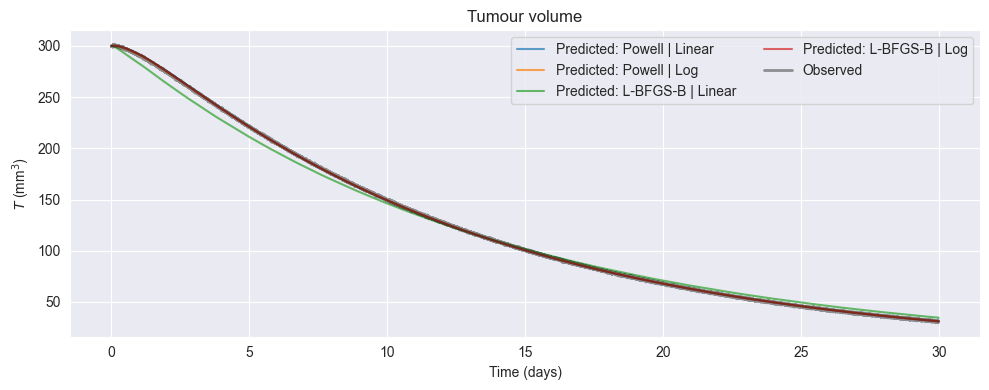

In [847]:
figure, axes = plt.subplots(figsize=(10,4))

for i in range(len(optimize_result_df)):
    if optimize_result_df.loc[i,'Log Scaled Params']=="Yes":
        log_lin_scale = "Log"
    elif optimize_result_df.loc[i,'Log Scaled Params']=="No":
        log_lin_scale = "Linear"
    axes.plot(optimize_result_df.loc[i,'Val Set Pred_time'], optimize_result_df.loc[i,'Val Set Pred'], 
               label=f'Predicted: {optimize_result_df.loc[i,'method_optimize']} | {log_lin_scale}', alpha=0.7) 

axes.plot(val_set_PK['t (days)'],val_set_PK['Tumor size obs'], label='Observed',alpha=0.4,color='black', lw=2)
axes.set_ylabel(r"$T$ (mm$^3$)")
axes.set_xlabel("Time (days)")
axes.set_title("Tumour volume")
axes.legend(ncols=2)
plt.tight_layout()
plt.show()

We find that three of the four fitted models essentially reproduce the held-out validation set tumor trajectory.

In [859]:
print(f"Validation Set MSE for optimizer ")
for i in range(len(optimize_result_df)):
    N = len(optimize_result_df.loc[i,'Val Set Pred'])
    val_MSE = np.sqrt(1/N*np.sum((optimize_result_df.loc[i,'Val Set Pred'] - val_set_PK['Tumor size obs'])**2))

    if optimize_result_df.loc[i,'Log Scaled Params']=="Yes":
        log_lin_scale = "Log"
    elif optimize_result_df.loc[i,'Log Scaled Params']=="No":
        log_lin_scale = "Linear"
    print(f"{optimize_result_df.loc[i,'method_optimize']}, {log_lin_scale} scale : {val_MSE:.4g} ")

Validation Set MSE for optimizer 
Powell, Linear scale : 0.6718 
Powell, Log scale : 0.5978 
L-BFGS-B, Linear scale : 5.505 
L-BFGS-B, Log scale : 0.6593 


Hence interestingly, the fitted models exhibit good predictive performance despite substantial deviations from the true generating parameters. This gives strong evidence of parameter non-identifiability.

Recovering the true parameters more accurately does not necessarily give better predictions, which is expected when different parameter combinations produce very similar model trajectories. For example, `CL` and `V` both affect the PK time scale and concentration magnitude. Emax and EC50 both determine the concentration-response curve. r and K jointly determine tumor growth. Several of these effects can compensate each other over the particular dose/time range in the training and validation regime.

To summarize, we find that predictive accuracy and parameter recovery do not necessarily follow from a single model. We find,

- Best tumor prediction by: Powell + log
- Best average parameter recovery by: BFGS + linear
- Best log-parameter recovery by: BFGS + linear
- Worst validation prediction by: BFGS + linear